In [1]:
import pickle

with open("X_train_w2v_cbow.pkl", "rb") as f:
    X_train = pickle.load(f)

with open("X_test_w2v_cbow.pkl", "rb") as f:
    X_test = pickle.load(f)

with open("y_train_w2v_cbow.pkl", "rb") as f:
    y_train = pickle.load(f)

with open("y_test_w2v_cbow.pkl", "rb") as f:
    y_test = pickle.load(f)

with open("w2v_model_cbow.pkl", "rb") as f:
    w2v_model_cbow = pickle.load(f)

  MODEL SELECTION WITH PROPER 5-FOLD CROSS VALIDATION

[STEP 1] Tuning hyperparameters with 5-fold CV on training data…


Tuning: LR
Best Params: {'C': 5}
CV Accuracy: 0.5964
Precision: 0.5919
Recall: 0.6329
F1 Score: 0.6117


Tuning: SVM Linear
Best Params: {'C': 1}
CV Accuracy: 0.5952
Precision: 0.5834
Recall: 0.6787
F1 Score: 0.6274


Tuning: SVM RBF
Best Params: {'C': 5, 'gamma': 'scale'}
CV Accuracy: 0.5980
Precision: 0.5893
Recall: 0.6587
F1 Score: 0.6221


Tuning: RF
Best Params: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 300}
CV Accuracy: 0.5964
Precision: 0.5899
Recall: 0.6444
F1 Score: 0.6159


[STEP 2] MODEL RANKING

     Model                                                    Best Params  CV Accuracy  CV Precision  CV Recall  CV F1
   SVM RBF                                     {'C': 5, 'gamma': 'scale'}       0.5980        0.5893     0.6587 0.6221
        LR                                                       {'C': 5}       0.5964        0.5919     0.6329

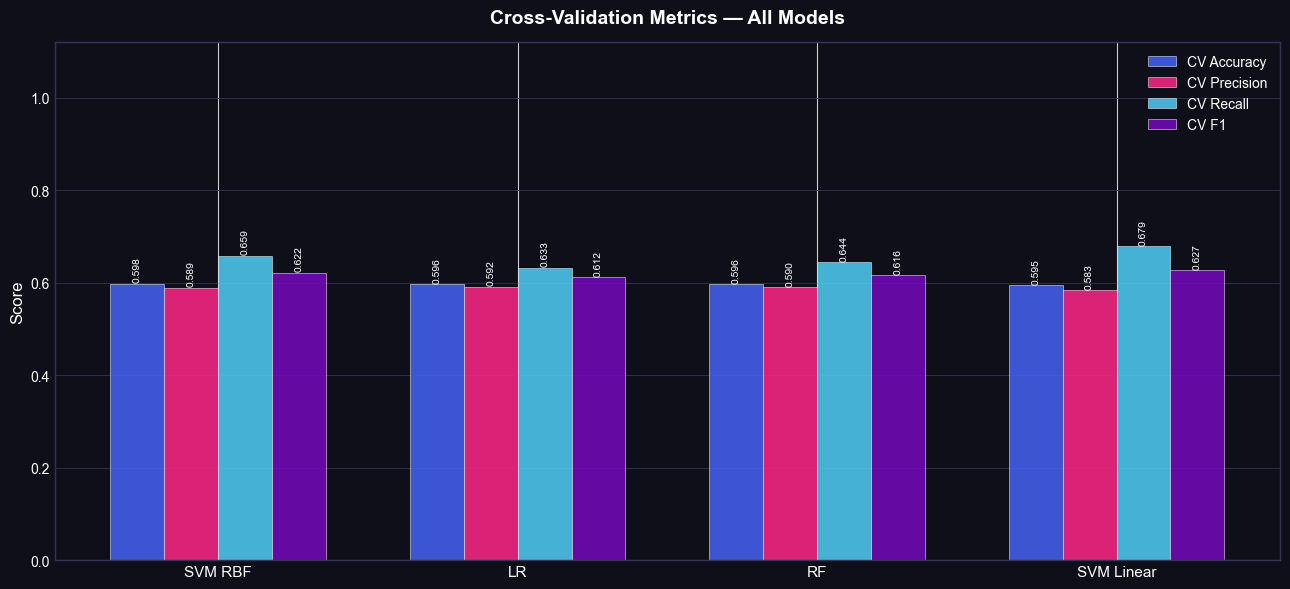

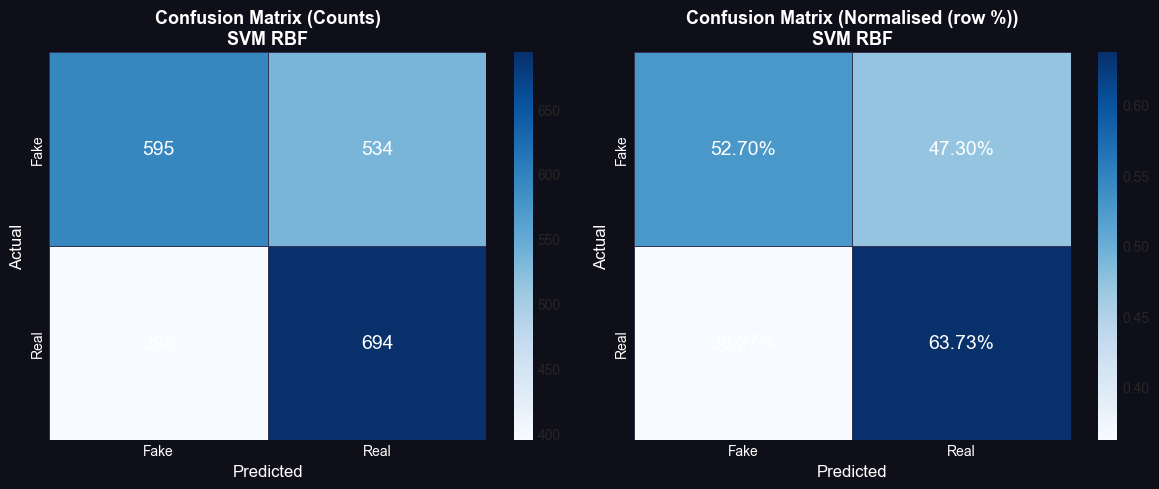

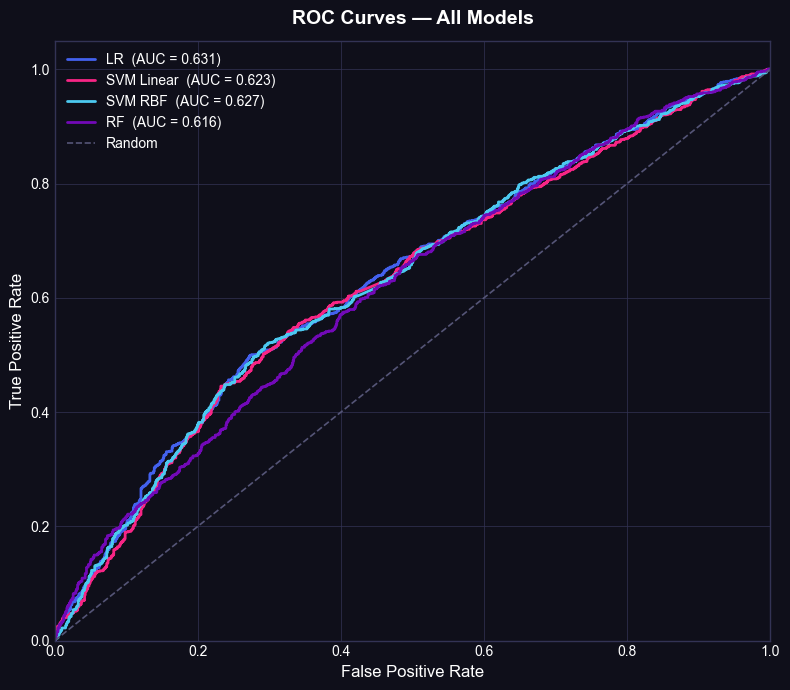

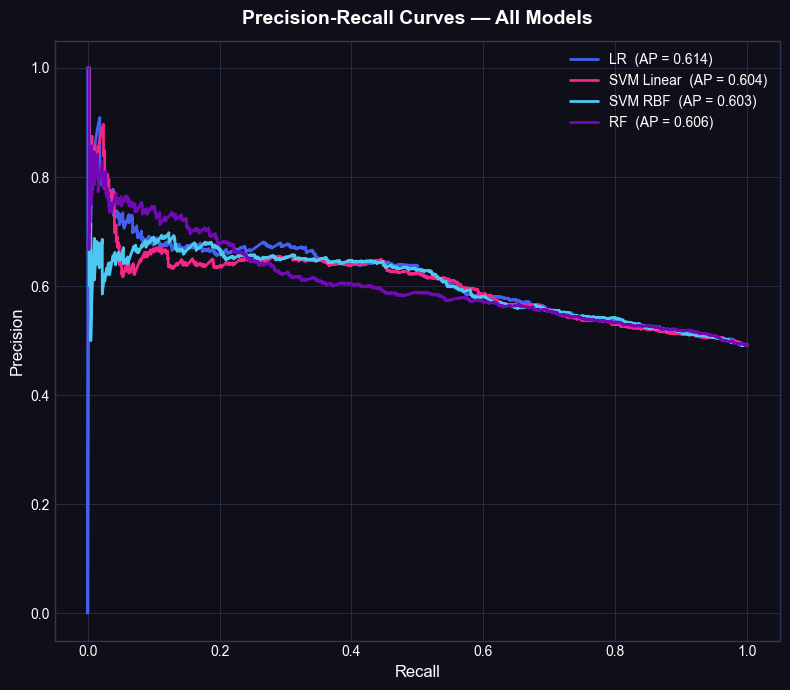

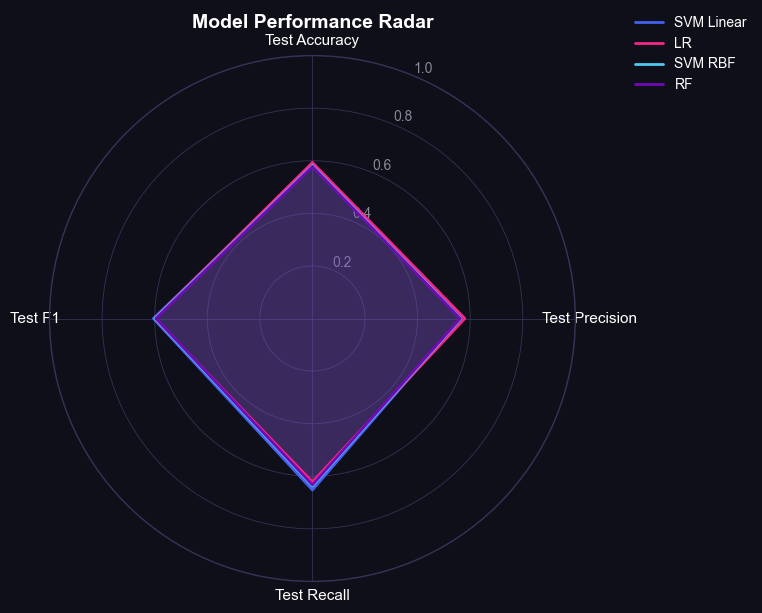

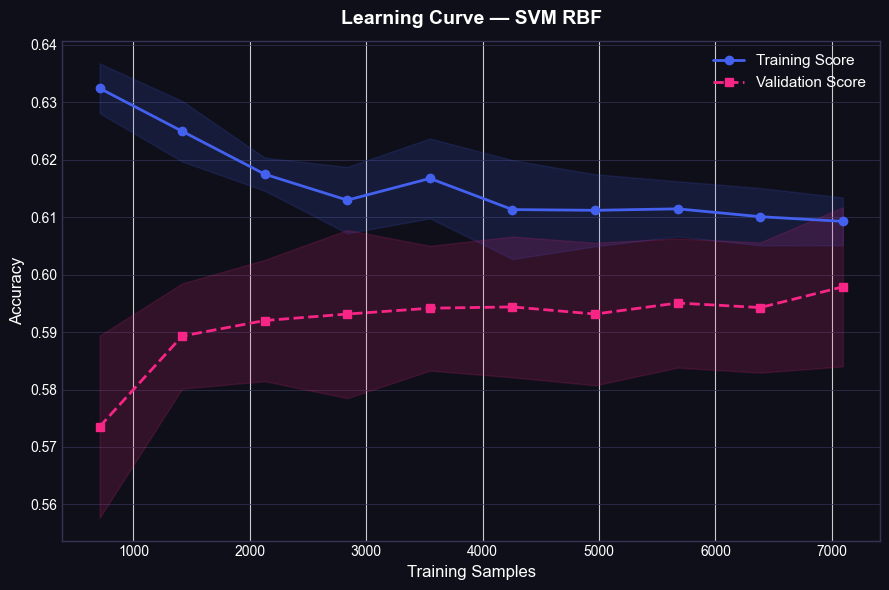

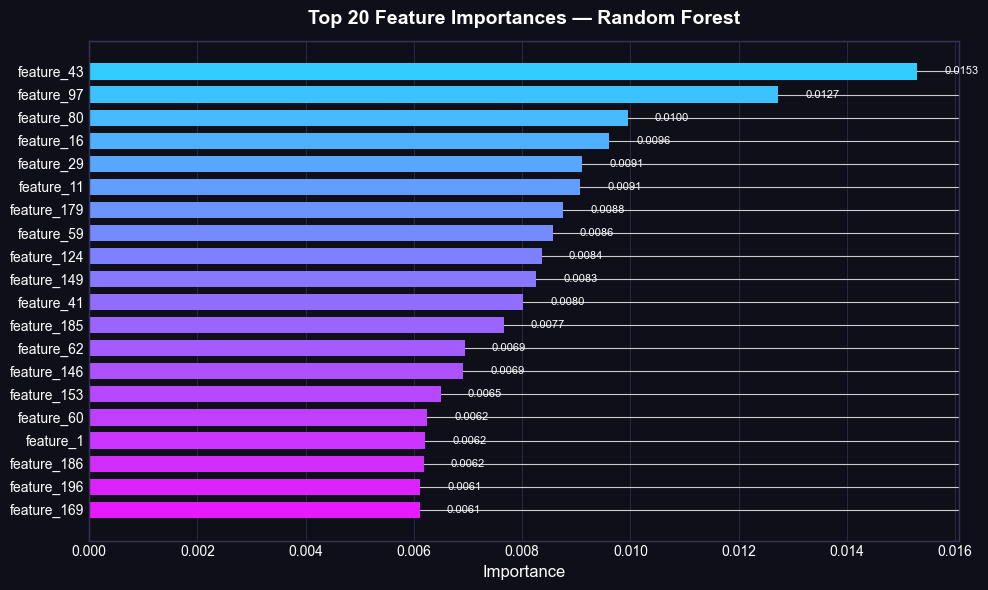

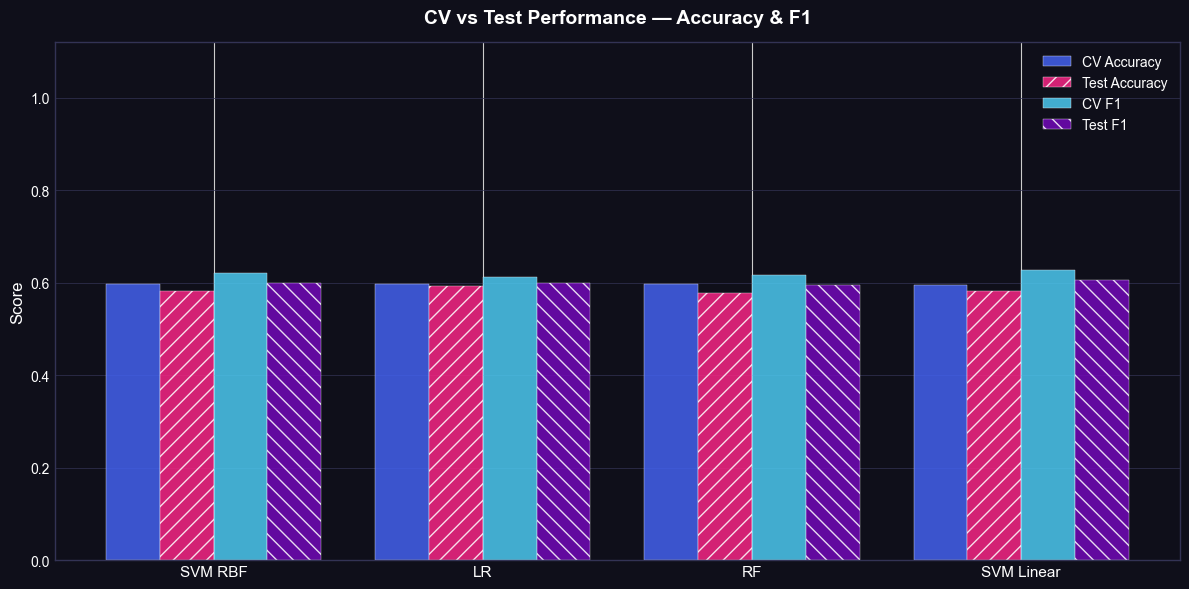

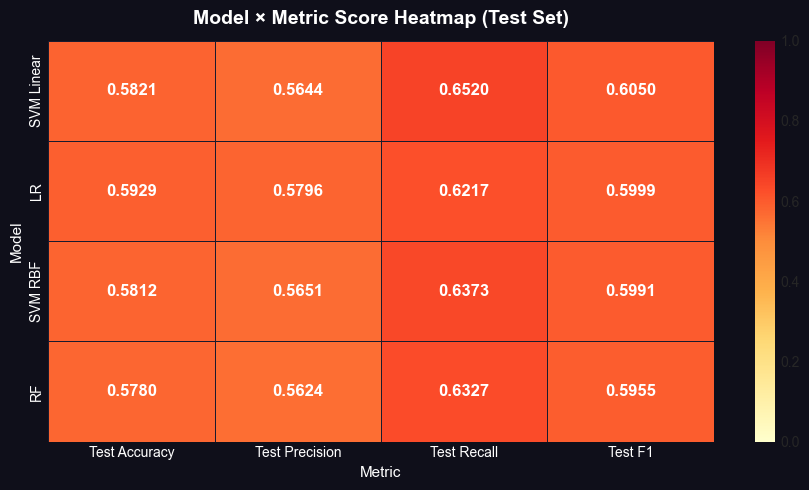

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, learning_curve
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    precision_recall_curve,
    average_precision_score
)
from sklearn.preprocessing import label_binarize

# ─────────────────────────────────────────────
#  PLOT STYLE
# ─────────────────────────────────────────────
plt.style.use("seaborn-v0_8-whitegrid")
PALETTE = ["#4361EE", "#F72585", "#4CC9F0", "#7209B7", "#3A0CA3"]
sns.set_palette(PALETTE)

# ─────────────────────────────────────────────
#  PARAMETER GRID
# ─────────────────────────────────────────────
param_grid = {
    "LR": {
        "model": LogisticRegression(max_iter=1000, random_state=42),
        "params": {"C": [0.1, 0.5, 1, 2, 5]}
    },
    "SVM Linear": {
        "model": SVC(kernel="linear", probability=True, random_state=42),
        "params": {"C": [0.1, 0.5, 1, 2, 5]}
    },
    "SVM RBF": {
        "model": SVC(kernel="rbf", probability=True, random_state=42),
        "params": {"C": [0.5, 1, 2, 5], "gamma": ["scale", "auto", 0.1]}
    },
    "RF": {
        "model": RandomForestClassifier(random_state=42),
        "params": {
            "n_estimators": [100, 200, 300],
            "max_depth": [10, 20, None],
            "min_samples_split": [2, 5, 10]
        }
    }
}

# ─────────────────────────────────────────────────────────────────────────────
#  HELPER: save figure
# ─────────────────────────────────────────────────────────────────────────────
def save_fig(fig, filename, dpi=150):
    fig.savefig(filename, dpi=dpi, bbox_inches="tight", facecolor=fig.get_facecolor())
    print(f"  [Saved] {filename}")


# ─────────────────────────────────────────────────────────────────────────────
#  PLOT 1 – Cross-Validation Metric Comparison (grouped bar chart)
# ─────────────────────────────────────────────────────────────────────────────
def plot_cv_metrics(df_results):
    metrics = ["CV Accuracy", "CV Precision", "CV Recall", "CV F1"]
    models  = df_results["Model"].tolist()
    x       = np.arange(len(models))
    width   = 0.18

    fig, ax = plt.subplots(figsize=(13, 6), facecolor="#0F0F1A")
    ax.set_facecolor("#0F0F1A")

    for i, (metric, color) in enumerate(zip(metrics, PALETTE)):
        vals = df_results[metric].values
        bars = ax.bar(x + i * width, vals, width, label=metric,
                      color=color, alpha=0.88, edgecolor="white", linewidth=0.4)
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.003,
                    f"{val:.3f}", ha="center", va="bottom",
                    fontsize=7.5, color="white", rotation=90)

    ax.set_xticks(x + width * 1.5)
    ax.set_xticklabels(models, color="white", fontsize=11)
    ax.set_ylim(0, 1.12)
    ax.set_ylabel("Score", color="white", fontsize=12)
    ax.set_title("Cross-Validation Metrics — All Models", color="white",
                 fontsize=14, fontweight="bold", pad=14)
    ax.tick_params(colors="white")
    ax.spines[:].set_color("#333355")
    ax.legend(framealpha=0.2, labelcolor="white", facecolor="#1A1A2E", fontsize=10)
    ax.yaxis.grid(True, color="#333355", linewidth=0.6)

    fig.tight_layout()
    save_fig(fig, "cv_metrics_comparison_20260130.png")
    return fig


# ─────────────────────────────────────────────────────────────────────────────
#  PLOT 2 – Confusion Matrix (best model)
# ─────────────────────────────────────────────────────────────────────────────
def plot_confusion_matrix(y_true, y_pred, model_name, class_names=("Fake", "Real")):
    cm   = confusion_matrix(y_true, y_pred)
    norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), facecolor="#0F0F1A")

    for ax, data, title, fmt in zip(
        axes,
        [cm, norm],
        ["Counts", "Normalised (row %)"],
        ["d", ".2%"]
    ):
        ax.set_facecolor("#0F0F1A")
        sns.heatmap(
            data, annot=True, fmt=fmt, ax=ax,
            cmap="Blues", linewidths=0.5, linecolor="#333355",
            xticklabels=class_names, yticklabels=class_names,
            annot_kws={"size": 14, "color": "white"}
        )
        ax.set_xlabel("Predicted", color="white", fontsize=12)
        ax.set_ylabel("Actual",    color="white", fontsize=12)
        ax.set_title(f"Confusion Matrix ({title})\n{model_name}",
                     color="white", fontsize=13, fontweight="bold")
        ax.tick_params(colors="white")
        for spine in ax.spines.values():
            spine.set_edgecolor("#333355")

    fig.tight_layout()
    save_fig(fig, f"confusion_matrix_{model_name.replace(' ', '_')}_20260130.png")
    return fig


# ─────────────────────────────────────────────────────────────────────────────
#  PLOT 3 – ROC Curves (all models)
# ─────────────────────────────────────────────────────────────────────────────
def plot_roc_curves(best_models, X_test, y_test):
    fig, ax = plt.subplots(figsize=(8, 7), facecolor="#0F0F1A")
    ax.set_facecolor("#0F0F1A")

    for (name, model), color in zip(best_models.items(), PALETTE):
        if hasattr(model, "predict_proba"):
            scores = model.predict_proba(X_test)[:, 1]
        elif hasattr(model, "decision_function"):
            scores = model.decision_function(X_test)
        else:
            continue
        fpr, tpr, _ = roc_curve(y_test, scores)
        roc_auc     = auc(fpr, tpr)
        ax.plot(fpr, tpr, color=color, lw=2,
                label=f"{name}  (AUC = {roc_auc:.3f})")

    ax.plot([0, 1], [0, 1], "--", color="#555577", lw=1.2, label="Random")
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel("False Positive Rate", color="white", fontsize=12)
    ax.set_ylabel("True Positive Rate",  color="white", fontsize=12)
    ax.set_title("ROC Curves — All Models", color="white",
                 fontsize=14, fontweight="bold", pad=12)
    ax.tick_params(colors="white")
    ax.spines[:].set_color("#333355")
    ax.yaxis.grid(True, color="#333355", linewidth=0.5)
    ax.xaxis.grid(True, color="#333355", linewidth=0.5)
    ax.legend(framealpha=0.2, labelcolor="white", facecolor="#1A1A2E", fontsize=10)

    fig.tight_layout()
    save_fig(fig, "roc_analysis_all_models_20260130.png")
    return fig


# ─────────────────────────────────────────────────────────────────────────────
#  PLOT 4 – Precision-Recall Curves (all models)
# ─────────────────────────────────────────────────────────────────────────────
def plot_pr_curves(best_models, X_test, y_test):
    fig, ax = plt.subplots(figsize=(8, 7), facecolor="#0F0F1A")
    ax.set_facecolor("#0F0F1A")

    for (name, model), color in zip(best_models.items(), PALETTE):
        if hasattr(model, "predict_proba"):
            scores = model.predict_proba(X_test)[:, 1]
        elif hasattr(model, "decision_function"):
            scores = model.decision_function(X_test)
        else:
            continue
        prec, rec, _ = precision_recall_curve(y_test, scores)
        ap           = average_precision_score(y_test, scores)
        ax.plot(rec, prec, color=color, lw=2,
                label=f"{name}  (AP = {ap:.3f})")

    ax.set_xlabel("Recall",    color="white", fontsize=12)
    ax.set_ylabel("Precision", color="white", fontsize=12)
    ax.set_title("Precision-Recall Curves — All Models", color="white",
                 fontsize=14, fontweight="bold", pad=12)
    ax.tick_params(colors="white")
    ax.spines[:].set_color("#333355")
    ax.yaxis.grid(True, color="#333355", linewidth=0.5)
    ax.xaxis.grid(True, color="#333355", linewidth=0.5)
    ax.legend(framealpha=0.2, labelcolor="white", facecolor="#1A1A2E", fontsize=10)

    fig.tight_layout()
    save_fig(fig, "precision_recall_curves_20260130.png")
    return fig


# ─────────────────────────────────────────────────────────────────────────────
#  PLOT 5 – Test-Set Metrics Radar Chart
# ─────────────────────────────────────────────────────────────────────────────
def plot_radar(comparison_df):
    metrics  = ["Test Accuracy", "Test Precision", "Test Recall", "Test F1"]
    n_metrics = len(metrics)
    angles   = np.linspace(0, 2 * np.pi, n_metrics, endpoint=False).tolist()
    angles  += angles[:1]

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"polar": True},
                           facecolor="#0F0F1A")
    ax.set_facecolor("#0F0F1A")
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(metrics, color="white", fontsize=11)
    ax.yaxis.set_tick_params(labelcolor="#888899")
    ax.set_ylim(0, 1)
    ax.spines["polar"].set_color("#333355")
    ax.yaxis.grid(color="#333355", linewidth=0.6)
    ax.xaxis.grid(color="#333355", linewidth=0.6)

    for (_, row), color in zip(comparison_df.iterrows(), PALETTE):
        vals  = row[metrics].tolist() + row[metrics].tolist()[:1]
        ax.plot(angles, vals, color=color, lw=2, label=row["Model"])
        ax.fill(angles, vals, color=color, alpha=0.12)

    ax.set_title("Model Performance Radar", color="white",
                 fontsize=14, fontweight="bold", pad=20)
    ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1),
              framealpha=0.2, labelcolor="white", facecolor="#1A1A2E", fontsize=10)

    fig.tight_layout()
    save_fig(fig, "performance_radar_chart_20260130.png")
    return fig


# ─────────────────────────────────────────────────────────────────────────────
#  PLOT 6 – Learning Curve (best model)
# ─────────────────────────────────────────────────────────────────────────────
def plot_learning_curve(model, X_train, y_train, model_name):
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train,
        cv=skf, scoring="accuracy",
        train_sizes=np.linspace(0.1, 1.0, 10),
        n_jobs=-1
    )

    train_mean = train_scores.mean(axis=1)
    train_std  = train_scores.std(axis=1)
    val_mean   = val_scores.mean(axis=1)
    val_std    = val_scores.std(axis=1)

    fig, ax = plt.subplots(figsize=(9, 6), facecolor="#0F0F1A")
    ax.set_facecolor("#0F0F1A")

    ax.plot(train_sizes, train_mean, "o-", color=PALETTE[0], lw=2, label="Training Score")
    ax.fill_between(train_sizes,
                    train_mean - train_std,
                    train_mean + train_std,
                    alpha=0.15, color=PALETTE[0])

    ax.plot(train_sizes, val_mean, "s--", color=PALETTE[1], lw=2, label="Validation Score")
    ax.fill_between(train_sizes,
                    val_mean - val_std,
                    val_mean + val_std,
                    alpha=0.15, color=PALETTE[1])

    ax.set_xlabel("Training Samples", color="white", fontsize=12)
    ax.set_ylabel("Accuracy",         color="white", fontsize=12)
    ax.set_title(f"Learning Curve — {model_name}", color="white",
                 fontsize=14, fontweight="bold", pad=12)
    ax.tick_params(colors="white")
    ax.spines[:].set_color("#333355")
    ax.yaxis.grid(True, color="#333355", linewidth=0.5)
    ax.legend(framealpha=0.2, labelcolor="white", facecolor="#1A1A2E", fontsize=11)

    fig.tight_layout()
    save_fig(fig, f"learning_curve_{model_name.replace(' ', '_')}_20260130.png")
    return fig


# ─────────────────────────────────────────────────────────────────────────────
#  PLOT 7 – Feature Importances (Random Forest only)
# ─────────────────────────────────────────────────────────────────────────────
def plot_feature_importance(rf_model, feature_names, top_n=20):
    importances = rf_model.feature_importances_
    idx         = np.argsort(importances)[::-1][:top_n]
    top_feats   = np.array(feature_names)[idx]
    top_vals    = importances[idx]

    fig, ax = plt.subplots(figsize=(10, 6), facecolor="#0F0F1A")
    ax.set_facecolor("#0F0F1A")

    colors = plt.cm.cool(np.linspace(0.2, 0.9, top_n))
    bars   = ax.barh(range(top_n), top_vals[::-1], color=colors[::-1],
                     edgecolor="none", height=0.7)

    ax.set_yticks(range(top_n))
    ax.set_yticklabels(top_feats[::-1], color="white", fontsize=10)
    ax.set_xlabel("Importance", color="white", fontsize=12)
    ax.set_title(f"Top {top_n} Feature Importances — Random Forest",
                 color="white", fontsize=14, fontweight="bold", pad=12)
    ax.tick_params(colors="white")
    ax.spines[:].set_color("#333355")
    ax.xaxis.grid(True, color="#333355", linewidth=0.5)

    for bar, val in zip(bars, top_vals[::-1]):
        ax.text(val + 0.0005, bar.get_y() + bar.get_height() / 2,
                f"{val:.4f}", va="center", color="white", fontsize=8)

    fig.tight_layout()
    save_fig(fig, "rf_feature_importance_analysis_20260130.png")
    return fig


# ─────────────────────────────────────────────────────────────────────────────
#  PLOT 8 – CV vs Test Score Comparison (dot-and-line)
# ─────────────────────────────────────────────────────────────────────────────
def plot_cv_vs_test(df_results, comparison_df):
    merged = pd.merge(
        df_results[["Model", "CV Accuracy", "CV F1"]],
        comparison_df[["Model", "Test Accuracy", "Test F1"]],
        on="Model"
    )

    x     = np.arange(len(merged))
    width = 0.2

    fig, ax = plt.subplots(figsize=(12, 6), facecolor="#0F0F1A")
    ax.set_facecolor("#0F0F1A")

    for i, (col, color, hatch) in enumerate(zip(
        ["CV Accuracy", "Test Accuracy", "CV F1", "Test F1"],
        PALETTE,
        ["", "//", "", "\\\\"]
    )):
        ax.bar(x + i * width, merged[col], width,
               label=col, color=color, alpha=0.85,
               hatch=hatch, edgecolor="white", linewidth=0.3)

    ax.set_xticks(x + width * 1.5)
    ax.set_xticklabels(merged["Model"], color="white", fontsize=11)
    ax.set_ylim(0, 1.12)
    ax.set_ylabel("Score", color="white", fontsize=12)
    ax.set_title("CV vs Test Performance — Accuracy & F1", color="white",
                 fontsize=14, fontweight="bold", pad=14)
    ax.tick_params(colors="white")
    ax.spines[:].set_color("#333355")
    ax.yaxis.grid(True, color="#333355", linewidth=0.5)
    ax.legend(framealpha=0.2, labelcolor="white", facecolor="#1A1A2E", fontsize=10)

    fig.tight_layout()
    save_fig(fig, "cv_test_performance_comparison_20260130.png")
    return fig


# ─────────────────────────────────────────────────────────────────────────────
#  PLOT 9 – Heatmap of all model × metric scores
# ─────────────────────────────────────────────────────────────────────────────
def plot_score_heatmap(comparison_df):
    metrics = ["Test Accuracy", "Test Precision", "Test Recall", "Test F1"]
    data    = comparison_df.set_index("Model")[metrics]

    fig, ax = plt.subplots(figsize=(9, 5), facecolor="#0F0F1A")
    ax.set_facecolor("#0F0F1A")

    sns.heatmap(
        data, annot=True, fmt=".4f", ax=ax,
        cmap="YlOrRd", linewidths=0.5, linecolor="#1A1A2E",
        annot_kws={"size": 12, "weight": "bold"},
        vmin=0, vmax=1
    )
    ax.set_title("Model × Metric Score Heatmap (Test Set)",
                 color="white", fontsize=14, fontweight="bold", pad=12)
    ax.set_xlabel("Metric", color="white", fontsize=11)
    ax.set_ylabel("Model",  color="white", fontsize=11)
    ax.tick_params(colors="white")
    for spine in ax.spines.values():
        spine.set_edgecolor("#333355")

    fig.tight_layout()
    save_fig(fig, "model_metric_heatmap_20260130.png")
    return fig

RESULTS_FILE = "model_analysis_results_20260130.txt"

open(RESULTS_FILE, "w", encoding="utf-8").close()

def save_to_txt(text=""):
    with open(RESULTS_FILE, "a", encoding="utf-8") as f:
        f.write(str(text) + "\n")


# ─────────────────────────────────────────────────────────────────────────────
# MAIN PIPELINE
# ─────────────────────────────────────────────────────────────────────────────

header = "=" * 65
print(header)
print("  MODEL SELECTION WITH PROPER 5-FOLD CROSS VALIDATION")
print(header)

save_to_txt(header)
save_to_txt("MODEL SELECTION WITH PROPER 5-FOLD CROSS VALIDATION")
save_to_txt(header)

# STEP 1 — Hyperparameter tuning
print("\n[STEP 1] Tuning hyperparameters with 5-fold CV on training data…\n")
save_to_txt("\n[STEP 1] Tuning hyperparameters with 5-fold CV")

results = []
best_models = {}

for model_name, model_params in param_grid.items():

    print(f"\nTuning: {model_name}")
    save_to_txt(f"\nTuning: {model_name}")

    skf = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    grid = GridSearchCV(
        estimator=model_params["model"],
        param_grid=model_params["params"],
        cv=skf,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    best_models[model_name] = grid.best_estimator_

    y_cv_pred = cross_val_predict(
        grid.best_estimator_,
        X_train,
        y_train,
        cv=skf,
        n_jobs=-1
    )

    cv_acc = accuracy_score(y_train, y_cv_pred)
    cv_prec = precision_score(y_train, y_cv_pred, average="binary")
    cv_rec = recall_score(y_train, y_cv_pred, average="binary")
    cv_f1 = f1_score(y_train, y_cv_pred, average="binary")

    results.append({
        "Model": model_name,
        "Best Params": grid.best_params_,
        "CV Accuracy": round(cv_acc,4),
        "CV Precision": round(cv_prec,4),
        "CV Recall": round(cv_rec,4),
        "CV F1": round(cv_f1,4)
    })

    txt = (
        f"Best Params: {grid.best_params_}\n"
        f"CV Accuracy: {cv_acc:.4f}\n"
        f"Precision: {cv_prec:.4f}\n"
        f"Recall: {cv_rec:.4f}\n"
        f"F1 Score: {cv_f1:.4f}\n"
    )

    print(txt)
    save_to_txt(txt)

# STEP 2 — Ranking
df_results = pd.DataFrame(results).sort_values(
    by="CV Accuracy",
    ascending=False
)

print("\n[STEP 2] MODEL RANKING\n")
print(df_results.to_string(index=False))

save_to_txt("\n[STEP 2] MODEL RANKING")
save_to_txt(df_results.to_string(index=False))

best_model_name = df_results.iloc[0]["Model"]
best_model = best_models[best_model_name]

selection_text = (
    f"\nSelected Best Model: {best_model_name}"
    f"\nCV Accuracy: {df_results.iloc[0]['CV Accuracy']:.4f}"
)

print(selection_text)
save_to_txt(selection_text)

# STEP 3 — Retraining
print("\n[STEP 3] Retraining best model...")
save_to_txt("\n[STEP 3] Retraining best model")

best_model.fit(X_train, y_train)

# STEP 4 — Final Test Evaluation
print("\n[STEP 4] FINAL TEST EVALUATION\n")
save_to_txt("\n[STEP 4] FINAL TEST EVALUATION")

y_pred = best_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_precision = precision_score(y_test, y_pred)
test_recall = recall_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred)

eval_text = (
    f"Test Accuracy : {test_accuracy:.4f}\n"
    f"Test Precision: {test_precision:.4f}\n"
    f"Test Recall   : {test_recall:.4f}\n"
    f"Test F1 Score : {test_f1:.4f}"
)

print(eval_text)
save_to_txt(eval_text)

report = classification_report(
    y_test,
    y_pred,
    target_names=["Fake","Real"]
)

print("\nClassification Report:\n")
print(report)

save_to_txt("\nClassification Report:")
save_to_txt(report)

# STEP 5 — Compare all models
print("\n[STEP 5] COMPARING ALL MODELS\n")
save_to_txt("\n[STEP 5] COMPARING ALL MODELS")

comparison_results = []

for model_name, estimator in best_models.items():

    estimator.fit(X_train, y_train)

    y_pred_model = estimator.predict(X_test)

    comparison_results.append({
        "Model": model_name,
        "Test Accuracy": round(
            accuracy_score(y_test,y_pred_model),4
        ),
        "Test Precision": round(
            precision_score(y_test,y_pred_model),4
        ),
        "Test Recall": round(
            recall_score(y_test,y_pred_model),4
        ),
        "Test F1": round(
            f1_score(y_test,y_pred_model),4
        )
    })

comparison_df = pd.DataFrame(
    comparison_results
).sort_values(
    by=["Test F1","Test Accuracy"],
    ascending=False
)

print(comparison_df.to_string(index=False))
save_to_txt(comparison_df.to_string(index=False))

best_test_model = comparison_df.iloc[0]

best_text = (
    f"\nBest Test Model: {best_test_model['Model']}\n"
    f"Accuracy : {best_test_model['Test Accuracy']}\n"
    f"Precision: {best_test_model['Test Precision']}\n"
    f"Recall   : {best_test_model['Test Recall']}\n"
    f"F1 Score : {best_test_model['Test F1']}"
)

print(best_text)
save_to_txt(best_text)

# STEP 6 — Generate plots
print("\n[STEP 6] GENERATING PLOTS...")
save_to_txt("\n[STEP 6] GENERATING PLOTS")

plot_cv_metrics(df_results)

plot_confusion_matrix(
    y_test,
    best_model.predict(X_test),
    best_model_name
)

plot_roc_curves(best_models, X_test, y_test)

plot_pr_curves(best_models, X_test, y_test)

plot_radar(comparison_df)

plot_learning_curve(
    best_model,
    X_train,
    y_train,
    best_model_name
)

if "RF" in best_models:

    rf_model = best_models["RF"]

    feature_names = (
        X_train.columns.tolist()
        if hasattr(X_train,"columns")
        else [f"feature_{i}" for i in range(X_train.shape[1])]
    )

    plot_feature_importance(
        rf_model,
        feature_names
    )

plot_cv_vs_test(df_results, comparison_df)

plot_score_heatmap(comparison_df)

print("\n✓ All plots saved successfully.")
print(header)

save_to_txt("\n✓ All plots saved successfully.")
save_to_txt(header)

In [3]:
import pickle

with open("best_w2v_cbow_liar.pkl", "wb") as f:
    pickle.dump(best_model, f)

print("Best model saved successfully")

Best model saved successfully
